# Classification et affectation - KaraFun

Suite de `analyse_avant_acm_v2.ipynb`. On reprend exactement là où le bilan (partie 14) s'est arrêté :

- **5 variables actives** : `anciennete_client_tr`, `anciennete_abonnement_tr`, `ratio_fidelite_tr`, `nb_abo_periode`, `valeur_12M_tr`
- **illustratives** : `type_client`, `contactable`, `type_first_abo_last_streak`, `type_very_first_abo`, `methode_paiement`, `zone_geo`, `avg_songs_sessions_tr`, `avg_sessions_actifs_tr`, `utilise_remote`
- échantillon de 20 % (`random_state=1`), avec les deux regroupements en plus de la partie 13.4

Plan (étapes 2 à 4 du cours) :

1. Reconstruction de l'échantillon
2. ACM finale : nombre d'axes et description des 4 premiers axes
3. CAH : choix du nombre de classes
4. Nuées dynamiques : consolidation des classes (classification mixte)
5. Description des classes (statistiques descriptives et tests)
6. Affectation : régression logistique généralisée et application à toute la base
7. Bilan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, adjusted_rand_score

pd.set_option("display.width", 200)

## 1. Reconstruction de l'échantillon

On relit le fichier regroupé enregistré par le notebook v2 (partie 9.8), puis on refait le même tirage de 20 % et les deux regroupements de la partie 13.4. La lecture du fichier Excel prend environ une minute.

In [2]:
df2 = pd.read_excel("../data/processed/td_clustering_karafun_modifie.xlsx")
print(df2.shape)

(341069, 16)


Les deux regroupements de la partie 13.4 du v2 sont mis dans une fonction, parce qu'il faudra les refaire sur toute la base au moment de l'affectation (partie 6).

In [3]:
def regroupements_acm(data):
    data = data.copy()
    data["anciennete_client_tr"] = data["anciennete_client_tr"].replace({
        "05_25a48_mois": "05_25_mois_et_plus",
        "06_49_mois_et_plus": "05_25_mois_et_plus",
    })
    data["avg_sessions_actifs_tr"] = data["avg_sessions_actifs_tr"].replace({
        "02_1a2": "02_1a5",
        "03_2a5": "02_1a5",
    })
    return data


ech = regroupements_acm(df2.sample(frac=0.2, random_state=1))
print(len(ech), "clients dans l'échantillon")

68214 clients dans l'échantillon


In [4]:
actives = [
    "anciennete_client_tr",
    "anciennete_abonnement_tr",
    "ratio_fidelite_tr",
    "nb_abo_periode",
    "valeur_12M_tr",
]

illustratives = [
    "type_client",
    "avg_sessions_actifs_tr",
    "avg_songs_sessions_tr",
    "utilise_remote",
    "methode_paiement",
    "zone_geo",
    "type_very_first_abo",
    "type_first_abo_last_streak",
    "contactable",
]

On retrouve bien les 68 214 clients du v2 : `sample` tire les lignes par leur position, et le fichier Excel a gardé l'ordre des lignes de `df2`.

## 2. ACM finale

Même calcul que la fonction `acm` du v2 (partie 13.1) : diagonalisation de la matrice tirée du tableau de Burt. On ajoute à la fin le calcul des **coordonnées des clients**, qui serviront d'entrée à la classification.

In [5]:
def acm(data, actives):
    Z = pd.get_dummies(data[actives], prefix_sep=" = ").astype(float)
    n = len(Z)
    Q = len(actives)
    J = Z.shape[1]

    poids = Z.sum() / (n * Q)
    m = (Z.T @ Z) / (n * Q**2) - np.outer(poids, poids)
    m = m / np.sqrt(np.outer(poids, poids))

    valeurs, vecteurs = np.linalg.eigh(m)
    ordre = np.argsort(valeurs)[::-1][:J - Q]
    valeurs = valeurs[ordre]
    vecteurs = vecteurs[:, ordre]
    axes = ["axe_" + str(k + 1) for k in range(J - Q)]

    vp = pd.DataFrame({"valeur_propre": valeurs}, index=axes)
    vp["pct_inertie"] = valeurs / valeurs.sum() * 100
    vp["pct_cumule"] = vp["pct_inertie"].cumsum()
    corrigees = np.where(valeurs > 1 / Q, (Q / (Q - 1)) ** 2 * (valeurs - 1 / Q) ** 2, 0)
    vp["pct_benzecri"] = corrigees / corrigees.sum() * 100
    vp["pct_benzecri_cumule"] = vp["pct_benzecri"].cumsum()

    coord = pd.DataFrame(vecteurs * np.sqrt(valeurs), index=Z.columns, columns=axes)
    coord = coord.div(np.sqrt(poids), axis=0)
    contrib = pd.DataFrame(vecteurs**2 * 100, index=Z.columns, columns=axes)

    return {"Z": Z, "Q": Q, "J": J, "valeurs": valeurs, "vp": vp,
            "coord": coord, "contrib": contrib, "frequence": Z.mean()}


def coord_clients(res, Z, nb_axes):
    # coordonnée d'un client = moyenne des coordonnées de ses modalités, divisée par racine(valeur propre)
    clients = (Z.values @ res["coord"].iloc[:, :nb_axes].values) / res["Q"]
    return clients / np.sqrt(res["valeurs"][:nb_axes])


res = acm(ech, actives)
res["vp"].round(2).head(10)

,valeur_propre,pct_inertie,pct_cumule,pct_benzecri,pct_benzecri_cumule
axe_1,0.68,14.80,14.80,50.70,50.70
axe_2,0.49,10.73,25.52,18.89,69.59
axe_3,0.44,9.53,35.05,12.46,82.05
axe_4,0.39,8.51,43.56,8.06,90.11
axe_5,0.37,8.09,51.66,6.52,96.63
axe_6,0.30,6.59,58.25,2.34,98.97
axe_7,0.27,5.78,64.03,0.95,99.93
axe_8,0.22,4.75,68.78,0.07,100.00
axe_9,0.20,4.37,73.15,0.00,100.00
axe_10,0.20,4.32,77.47,0.00,100.00


On retrouve les valeurs propres du v2 (0,681 ; 0,493 ; 0,438...).

### 2.1 Combien d'axes garder ?

Le cours donne trois critères (diapo « ACM : questions pratiques ») :

In [6]:
nb_axes_total = res["J"] - res["Q"]
inertie_moyenne = 100 / nb_axes_total
vp = res["vp"]

print("nombre d'axes :", nb_axes_total, "-> information moyenne par axe :", round(inertie_moyenne, 2), "%")
print("critère 1, axes au-dessus de la moyenne        :", (vp["pct_inertie"] > inertie_moyenne).sum())
print("critère 2, axes pour atteindre 50 % d'inertie  :", (vp["pct_cumule"] < 50).sum() + 1)
print("critère 3, axes pour 95 % d'inertie Benzécri   :", (vp["pct_benzecri_cumule"] < 95).sum() + 1)

nombre d'axes : 23 -> information moyenne par axe : 4.35 %
critère 1, axes au-dessus de la moyenne        : 9
critère 2, axes pour atteindre 50 % d'inertie  : 5
critère 3, axes pour 95 % d'inertie Benzécri   : 5


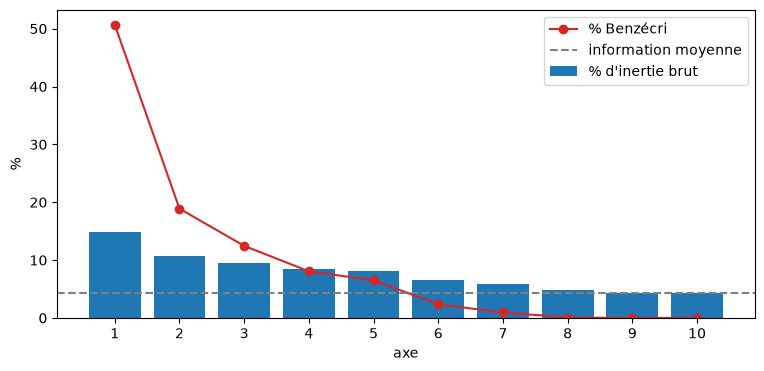

In [7]:
plt.figure(figsize=(9, 4))
plt.bar(range(1, 11), vp["pct_inertie"][:10], label="% d'inertie brut")
plt.plot(range(1, 11), vp["pct_benzecri"][:10], "o-", color="tab:red", label="% Benzécri")
plt.axhline(inertie_moyenne, color="grey", linestyle="--", label="information moyenne")
plt.xticks(range(1, 11))
plt.xlabel("axe")
plt.ylabel("%")
plt.legend()
plt.show()

**Décision : on garde 5 axes.**

- Le critère « 50 % de l'inertie » donne 5 axes (51,6 % cumulés).
- Le critère Benzécri, utilisé dans tout le v2, donne aussi 5 axes (96,6 %). Après le 5e axe, les axes corrigés ne portent presque plus rien (2,3 % puis moins de 1 %).
- Le critère « au-dessus de la moyenne » en donne 9. Il est connu pour être trop généreux en ACM : les pourcentages bruts sont tous faibles et proches les uns des autres, donc beaucoup d'axes passent la moyenne de justesse. Les axes 6 à 9 ne font que 6,6 %, 5,8 %, 4,8 % et 4,4 %, et la correction de Benzécri montre qu'ils ne contiennent presque pas d'information (2,3 % pour l'axe 6, moins de 1 % ensuite).

Deux critères sur trois donnent 5 axes. On garde donc 5 axes : ils résument presque toute l'information utile, et ils enlèvent le « bruit » des derniers axes avant la classification.

### 2.2 Description des 4 premiers axes

Pour chaque axe, on garde les modalités dont la contribution dépasse la contribution moyenne (100 / J), et on les trie par coordonnée : les modalités d'un même côté de l'axe vont ensemble.

In [8]:
def modalites_axe(res, axe):
    tableau = pd.DataFrame({
        "pct_clients": res["frequence"] * 100,
        "coordonnee": res["coord"][axe],
        "contribution": res["contrib"][axe],
    })
    tableau = tableau[tableau["contribution"] > 100 / res["J"]]
    return tableau.sort_values("coordonnee")


print("contribution moyenne :", round(100 / res["J"], 2))
modalites_axe(res, "axe_1").round(2)

contribution moyenne : 3.57


,pct_clients,coordonnee,contribution
valeur_12M_tr = 01_moins_10,28.90,-1.07,9.70
nb_abo_periode = 01_1_abo,28.76,-1.07,9.62
ratio_fidelite_tr = 01_moins_30,27.69,-0.87,6.20
anciennete_client_tr = 05_25_mois_et_plus,32.94,0.70,4.68
ratio_fidelite_tr = 05_90_et_plus,35.81,0.74,5.71
anciennete_abonnement_tr = 04_13a24_mois,13.06,1.10,4.66
valeur_12M_tr = 05_70a90,15.72,1.36,8.49
nb_abo_periode = 05_12_abo,20.88,1.54,14.48
anciennete_abonnement_tr = 05_25_mois_et_plus,12.27,1.56,8.80
valeur_12M_tr = 07_110_et_plus,6.77,1.64,5.37


**Axe 1 (50,7 % Benzécri) : l'engagement.** À gauche, les clients qui ne se sont abonnés qu'un mois sur la période et ont rapporté moins de 10 (même point, -1,07 : ce sont les mêmes clients), avec un ratio de fidélité sous 30 %. À droite, les abonnés des 12 mois, à forte valeur (70 et plus), abonnés sans interruption depuis plus d'un an, avec un ratio de fidélité de 90 % et plus. C'est l'axe principal : il range les clients du moins au plus engagé.

In [9]:
modalites_axe(res, "axe_2").round(2)

,pct_clients,coordonnee,contribution
nb_abo_periode = 03_4a6_abo,14.39,-1.57,14.36
valeur_12M_tr = 03_20a40,14.43,-1.46,12.43
anciennete_client_tr = 02_3a5_mois,9.50,-1.24,5.96
anciennete_abonnement_tr = 02_3a5_mois,15.59,-1.13,8.03
nb_abo_periode = 05_12_abo,20.88,0.74,4.58
valeur_12M_tr = 01_moins_10,28.90,0.76,6.69
nb_abo_periode = 01_1_abo,28.76,0.76,6.74
anciennete_client_tr = 01_moins_3_mois,10.49,1.42,8.59
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,2.40,8.59


**Axe 2 (18,9 %) : le milieu contre les extrêmes.** En bas, les clients « intermédiaires » : 4 à 6 mois d'abonnement, 20 à 40 de valeur, abonnés depuis 3 à 5 mois. En haut, à la fois les clients à 1 mois et ceux à 12 mois, et surtout les nouveaux arrivants (vient de s'abonner, 2,40 ; client depuis moins de 3 mois). C'est l'effet Guttman déjà vu dans le v2 : l'axe 2 isole le milieu de l'axe 1.

In [10]:
modalites_axe(res, "axe_3").round(2)

,pct_clients,coordonnee,contribution
anciennete_client_tr = 01_moins_3_mois,10.49,-1.66,13.18
ratio_fidelite_tr = 99_vient_de_s_abonner,3.68,-1.65,4.58
anciennete_abonnement_tr = 01_moins_3_mois,20.44,-1.11,11.58
nb_abo_periode = 02_2a3_abo,19.34,-0.91,7.30
valeur_12M_tr = 02_10a20,15.85,-0.89,5.76
ratio_fidelite_tr = 01_moins_30,27.69,0.73,6.75
valeur_12M_tr = 04_40a70,15.90,0.78,4.43
anciennete_client_tr = 03_6a12_mois,28.66,0.84,9.26
anciennete_abonnement_tr = 03_6a12_mois,38.64,0.86,12.94
nb_abo_periode = 04_7a11_abo,16.62,0.95,6.79


**Axe 3 (12,5 %) : l'ancienneté, à engagement égal.** À gauche, les clients récents : client et abonnement de moins de 3 mois, 2 à 3 mois d'abonnement, 10 à 20 de valeur. À droite, les clients arrivés il y a 6 à 12 mois : soit ceux qui sont restés 7 à 11 mois, soit ceux qui ne sont restés qu'un mois (ratio sous 30 %). Cet axe sépare donc les clients qui **commencent** de ceux qui ont **déjà fait leur choix**.

In [11]:
modalites_axe(res, "axe_4").round(2)

,pct_clients,coordonnee,contribution
anciennete_client_tr = 02_3a5_mois,9.50,-1.58,12.09
anciennete_abonnement_tr = 02_3a5_mois,15.59,-1.10,9.68
nb_abo_periode = 03_4a6_abo,14.39,-0.95,6.70
valeur_12M_tr = 03_20a40,14.43,-0.74,3.99
nb_abo_periode = 01_1_abo,28.76,-0.62,5.72
valeur_12M_tr = 01_moins_10,28.90,-0.62,5.59
nb_abo_periode = 04_7a11_abo,16.62,0.72,4.44
nb_abo_periode = 02_2a3_abo,19.34,1.35,17.91
valeur_12M_tr = 02_10a20,15.85,1.55,19.36


**Axe 4 (8,1 %) : les « testeurs » courts.** Il isole les clients à 2-3 mois d'abonnement et 10 à 20 de valeur (à droite, 37 % de l'axe à eux deux), opposés aux clients à 4-6 mois arrivés il y a 3 à 5 mois et aux clients à 1 mois.

**À retenir :** les axes ne parlent que de l'abonnement (durée, valeur, ancienneté, régularité), c'est la conséquence du choix des variables actives. L'axe 1 porte la moitié de l'information ; les axes 2 à 4 découpent les clients « du milieu » en sous-profils. On s'attend donc à des classes rangées le long de l'engagement.

### 2.3 Coordonnées des clients

Chaque client reçoit 5 coordonnées (une par axe gardé). C'est ce tableau, quantitatif, qui sert de base à la classification : c'est le rôle de l'ACM dans la méthode du cours (transformer des variables qualitatives en coordonnées).

In [12]:
nb_axes = 5
axes = ["axe_" + str(k + 1) for k in range(nb_axes)]

X = coord_clients(res, res["Z"], nb_axes)
X = pd.DataFrame(X, index=ech.index, columns=axes)

# vérification : la variance des clients sur un axe est égale à la valeur propre
print(X.var(ddof=0).round(3).tolist())
print(res["valeurs"][:nb_axes].round(3).tolist())

[0.681, 0.493, 0.438, 0.392, 0.372]
[0.681, 0.493, 0.438, 0.392, 0.372]


In [13]:
nb_profils = ech[actives].drop_duplicates().shape[0]
print(nb_profils, "profils différents parmi", len(ech), "clients")

607 profils différents parmi 68214 clients


Les 68 214 clients n'ont que 607 combinaisons différentes de modalités actives : beaucoup de clients ont exactement les mêmes coordonnées. C'est normal avec 5 variables qualitatives, et cela explique pourquoi la classification sera très stable.

## 3. CAH : choix du nombre de classes

### 3.1 Pourquoi une CAH sur un sous-échantillon ?

La CAH calcule la distance entre tous les couples de clients. Pour 68 214 clients, cela fait 2,3 milliards de distances (environ 18 Go de mémoire) : impossible sur un ordinateur portable. C'est l'inconvénient de la CAH donné dans le cours (« temps de traitement long »).

On fait donc la **classification mixte** du cours :
1. CAH (méthode de Ward, comme `proc cluster method=ward`) sur **10 000 clients tirés au hasard** dans l'échantillon, pour choisir le nombre de classes ;
2. nuées dynamiques (k-means, comme `proc fastclus`) sur les **68 214 clients**, en partant des centres des classes de la CAH (partie 4).

Pour vérifier que le tirage des 10 000 clients ne change pas le résultat, on fait la CAH sur deux sous-échantillons différents.

In [14]:
sous_ech_1 = X.sample(10000, random_state=1)
sous_ech_2 = X.sample(10000, random_state=2)

arbre_1 = linkage(sous_ech_1, method="ward")
arbre_2 = linkage(sous_ech_2, method="ward")

### 3.2 Dendrogramme

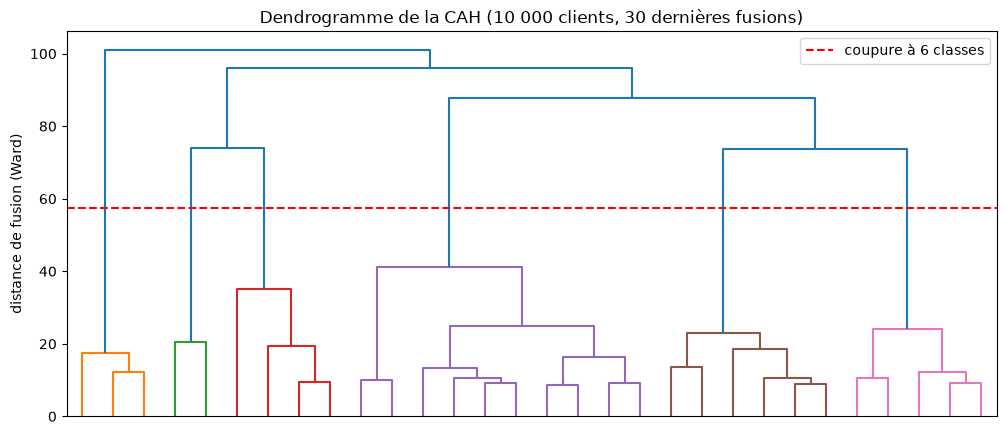

In [15]:
# hauteur de coupure : entre la fusion qui donne 6 classes et celle qui donne 5 classes
coupure = (arbre_1[-6, 2] + arbre_1[-5, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(arbre_1, truncate_mode="lastp", p=30, no_labels=True, color_threshold=coupure)
plt.axhline(coupure, color="red", linestyle="--", label="coupure à 6 classes")
plt.ylabel("distance de fusion (Ward)")
plt.title("Dendrogramme de la CAH (10 000 clients, 30 dernières fusions)")
plt.legend()
plt.savefig("../outputs/figures/cah_dendrogramme.png", dpi=100, bbox_inches="tight")
plt.show()

Le dendrogramme montre de grandes branches jusqu'à 6 classes, puis des fusions beaucoup plus basses : en dessous de la ligne rouge, les classes qu'on séparerait se ressemblent beaucoup.

### 3.3 Indicateurs : R², R² semi-partiel et pseudo-F

- **R²** : part de l'inertie expliquée par la partition (inertie entre les classes / inertie totale). Il augmente toujours avec le nombre de classes, on cherche le moment où il cesse d'augmenter beaucoup.
- **R² semi-partiel (SPRSQ)** : perte de R² quand on regroupe deux classes pour passer de k à k-1 classes. Un SPRSQ fort pour la fusion qui donne k-1 classes veut dire qu'il ne faut pas faire cette fusion. On cherche le décrochage.
- **pseudo-F** : rapport entre l'inertie entre les classes et l'inertie dans les classes, corrigé du nombre de classes. Il est donné aussi par `proc cluster` (PSF). Un pic indique un bon nombre de classes.

Le CCC (cubic clustering criterion) du cours est propre à SAS et n'existe pas dans les librairies Python courantes ; le pseudo-F joue un rôle proche.

Avec la méthode de Ward, la hauteur d'une fusion h correspond à une perte d'inertie de h² / 2. Le SPRSQ s'en déduit directement.

In [16]:
def indicateurs(points, arbre):
    points = points.values
    inertie_totale = ((points - points.mean(axis=0)) ** 2).sum()
    n = len(points)
    lignes = []
    for k in range(2, 11):
        classes = fcluster(arbre, k, criterion="maxclust")
        inertie_intra = 0
        for c in np.unique(classes):
            groupe = points[classes == c]
            inertie_intra += ((groupe - groupe.mean(axis=0)) ** 2).sum()
        r2 = 1 - inertie_intra / inertie_totale
        # fusion qui fait passer de k à k-1 classes
        sprsq = arbre[-(k - 1), 2] ** 2 / 2 / inertie_totale
        pseudo_f = (r2 / (k - 1)) / ((1 - r2) / (n - k))
        lignes.append([k, r2, sprsq, pseudo_f, sorted(np.bincount(classes)[1:], reverse=True)])
    return pd.DataFrame(lignes, columns=["nb_classes", "R2", "SPRSQ", "pseudo_F", "effectifs"]).set_index("nb_classes")


indic_1 = indicateurs(sous_ech_1, arbre_1)
indic_2 = indicateurs(sous_ech_2, arbre_2)
indic_1.round(3)

,R2,SPRSQ,pseudo_F,effectifs
nb_classes,,,,
2,0.214,0.214,2727.546,"[8030, 1970]"
3,0.407,0.193,3434.703,"[5268, 2762, 1970]"
4,0.569,0.162,4405.487,"[3234, 2762, 2034, 1970]"
5,0.684,0.115,5409.914,"[3234, 2104, 2034, 1970, 658]"
6,0.798,0.114,7891.657,"[2104, 2034, 1988, 1970, 1246, 658]"
7,0.834,0.036,8344.854,"[2104, 1988, 1970, 1605, 1246, 658, 429]"
8,0.860,0.026,8739.480,"[1988, 1970, 1730, 1605, 1246, 658, 429, 374]"
9,0.873,0.013,8547.759,"[1988, 1970, 1730, 1246, 971, 658, 634, 429, 374]"
10,0.885,0.012,8521.855,"[1988, 1970, 1730, 971, 694, 658, 634, 552, 42..."


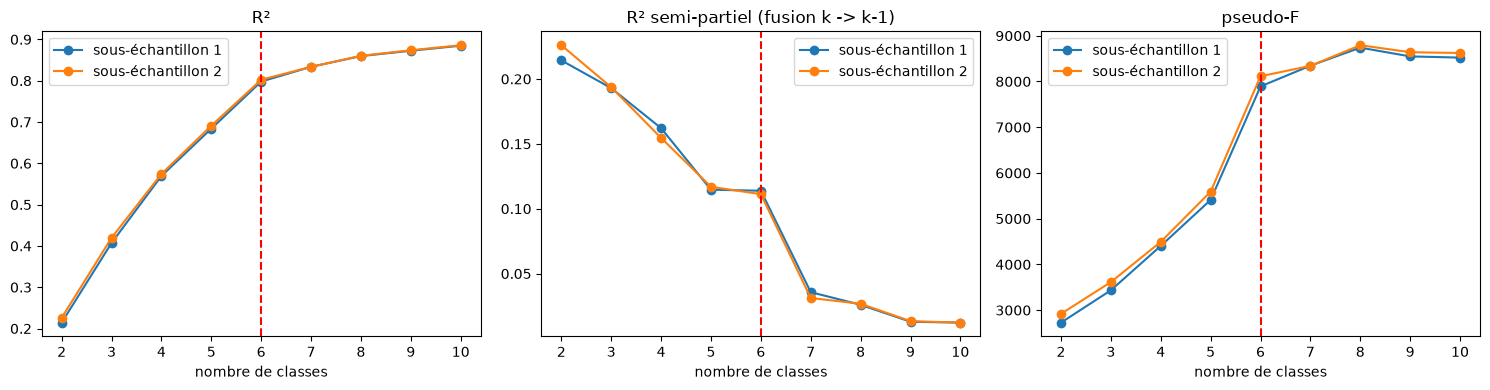

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for indic, nom in [(indic_1, "sous-échantillon 1"), (indic_2, "sous-échantillon 2")]:
    ax[0].plot(indic.index, indic["R2"], "o-", label=nom)
    ax[1].plot(indic.index, indic["SPRSQ"], "o-", label=nom)
    ax[2].plot(indic.index, indic["pseudo_F"], "o-", label=nom)
for a, titre in zip(ax, ["R²", "R² semi-partiel (fusion k -> k-1)", "pseudo-F"]):
    a.axvline(6, color="red", linestyle="--")
    a.set_title(titre)
    a.set_xlabel("nombre de classes")
    a.legend()
plt.tight_layout()
plt.savefig("../outputs/figures/cah_indicateurs.png", dpi=100, bbox_inches="tight")
plt.show()

In [18]:
indic_2.round(3)

,R2,SPRSQ,pseudo_F,effectifs
nb_classes,,,,
2,0.226,0.226,2919.768,"[7898, 2102]"
3,0.420,0.194,3614.151,"[4980, 2918, 2102]"
4,0.574,0.155,4493.407,"[3124, 2918, 2102, 1856]"
5,0.691,0.117,5590.972,"[3124, 2243, 2102, 1856, 675]"
6,0.802,0.111,8113.786,"[2243, 2102, 1856, 1819, 1305, 675]"
7,0.834,0.031,8341.309,"[2243, 2102, 1819, 1485, 1305, 675, 371]"
8,0.860,0.027,8792.760,"[2102, 1858, 1819, 1485, 1305, 675, 385, 371]"
9,0.874,0.013,8639.349,"[2102, 1858, 1819, 1305, 944, 675, 541, 385, 371]"
10,0.886,0.012,8622.240,"[2102, 1858, 1819, 944, 742, 675, 563, 541, 38..."


**Décision : 6 classes.**

- **SPRSQ** : passer de 6 à 5 classes coûterait 11,4 % de l'inertie, alors que passer de 7 à 6 ne coûte que 3,6 % (11,1 % et 3,1 % sur le second sous-échantillon). C'est le décrochage le plus net de la courbe (« un pic suivi d'un creux » dans le cours) : couper en 6 garde des classes bien séparées, couper plus loin n'apporte presque rien.
- **R²** : il monte vite jusqu'à 6 classes (0,80), puis lentement (0,84 à 7 classes, 0,89 à 10). La 7e classe n'apporte que 3 points.
- **pseudo-F** : il fait un grand saut entre 5 et 6 classes (de 5 410 à 7 892, +46 %), puis il n'augmente presque plus (+6 % à 7 classes, +5 % à 8, puis il baisse). Il n'a pas de pic net à 6, mais il confirme que la 6e classe est la dernière qui améliore vraiment la partition.
- **Stabilité** : les deux sous-échantillons donnent les mêmes valeurs à 0,01 près et des classes de même taille.
- **Côté métier** : 6 profils, c'est un nombre que l'équipe marketing peut retenir et pour lesquels elle peut construire des actions différentes.

## 4. Nuées dynamiques : consolidation sur tout l'échantillon

On calcule le centre (point moyen) de chacune des 6 classes de la CAH, puis on lance les k-means sur les 68 214 clients **en partant de ces centres** (`init=centres`). Les k-means vont :
- donner une classe à tous les clients de l'échantillon (la CAH n'en a classé que 10 000) ;
- corriger les quelques clients mal placés par la CAH (la CAH ne revient jamais sur une fusion, les k-means oui).

In [19]:
classes_cah = fcluster(arbre_1, 6, criterion="maxclust")
centres_cah = sous_ech_1.groupby(classes_cah).mean()
centres_cah.round(2)

,axe_1,axe_2,axe_3,axe_4,axe_5
1,1.27,0.53,-0.09,-0.20,0.35
2,-1.09,1.36,-0.91,-0.29,-0.99
3,-0.82,0.29,0.63,-0.44,0.36
4,-0.41,-0.26,-0.59,0.86,0.50
5,0.41,-0.31,0.56,0.40,-0.82
6,-0.04,-1.17,-0.43,-0.71,-0.19


In [20]:
kmeans = KMeans(n_clusters=6, init=centres_cah.values, n_init=1).fit(X)
print("nombre d'itérations :", kmeans.n_iter_)

inertie_totale = ((X - X.mean()) ** 2).sum().sum()
print("R² après consolidation :", round(1 - kmeans.inertia_ / inertie_totale, 3))

nombre d'itérations : 3
R² après consolidation : 0.809


Les k-means ont convergé en très peu d'itérations : les centres de départ étaient déjà presque à l'équilibre. Le R² sur les 68 214 clients (0,81) est le même que celui de la CAH sur 10 000 clients.

### 4.1 Les classes changent-elles avec la consolidation ?

On compare la classe de la CAH (centre le plus proche parmi les centres de la CAH) avec la classe après k-means.

In [21]:
distances = ((X.values[:, None, :] - centres_cah.values[None, :, :]) ** 2).sum(axis=2)
classe_avant = distances.argmin(axis=1)

pd.crosstab(classe_avant, kmeans.labels_, rownames=["CAH"], colnames=["k-means"])

k-means,0,1,2,3,4,5
CAH,,,,,,
0,14372,0,0,0,0,0
1,0,4568,0,0,0,0
2,0,0,14275,0,0,11
3,0,0,0,12622,0,84
4,25,0,0,0,12443,3
5,0,0,0,0,0,9811


Presque tous les clients restent dans leur classe : les k-means n'ont déplacé que 123 clients sur 68 214 (0,2 %), à la frontière de deux classes voisines.

### 4.2 Tests de stabilité

On vérifie que la partition ne dépend pas de nos choix techniques, avec l'indice de Rand ajusté (ARI : 1 = partitions identiques, 0 = aucun lien) :
- en partant de la CAH du sous-échantillon 2 au lieu du sous-échantillon 1 ;
- avec des k-means classiques (10 départs au hasard, sans la CAH).

In [22]:
classes_cah_2 = fcluster(arbre_2, 6, criterion="maxclust")
centres_cah_2 = sous_ech_2.groupby(classes_cah_2).mean()
kmeans_2 = KMeans(n_clusters=6, init=centres_cah_2.values, n_init=1).fit(X)

kmeans_hasard = KMeans(n_clusters=6, n_init=10, random_state=0).fit(X)

print("ARI sous-échantillon 1 / sous-échantillon 2 :", round(adjusted_rand_score(kmeans.labels_, kmeans_2.labels_), 3))
print("ARI CAH + k-means / k-means au hasard      :", round(adjusted_rand_score(kmeans.labels_, kmeans_hasard.labels_), 3))

ARI sous-échantillon 1 / sous-échantillon 2 : 1.0
ARI CAH + k-means / k-means au hasard      : 0.998


Les trois méthodes trouvent la même partition (ARI de 1 et 0,998). Les 6 classes ne sont pas un hasard de calcul : elles existent vraiment dans les données.

### 4.3 Numérotation des classes

Les numéros donnés par la CAH n'ont pas de sens. On renumérote les classes de la moins engagée à la plus engagée, c'est-à-dire selon la position moyenne de leurs clients sur l'axe 1 (l'axe de l'engagement, partie 2.2). La classe 1 sera la moins engagée, la classe 6 la plus engagée.

In [23]:
position_axe_1 = X["axe_1"].groupby(kmeans.labels_).mean().sort_values()
nouveau_numero = {ancien: rang + 1 for rang, ancien in enumerate(position_axe_1.index)}

ech["cluster"] = pd.Series(kmeans.labels_, index=ech.index).map(nouveau_numero)

print(X["axe_1"].groupby(ech["cluster"]).mean().round(2))

cluster
1   -1.09
2   -0.82
3   -0.42
4   -0.11
5    0.38
6    1.27
Name: axe_1, dtype: float64


In [24]:
effectifs = ech["cluster"].value_counts().sort_index()
pd.DataFrame({"effectif": effectifs, "pct": (effectifs / len(ech) * 100).round(1)})

,effectif,pct
cluster,,
1,4568,6.7
2,14275,20.9
3,12622,18.5
4,9909,14.5
5,12443,18.2
6,14397,21.1


Les classes sont de tailles équilibrées (de 7 % à 21 %) : pas de classe minuscule qu'on ne pourrait pas cibler, pas de classe fourre-tout.

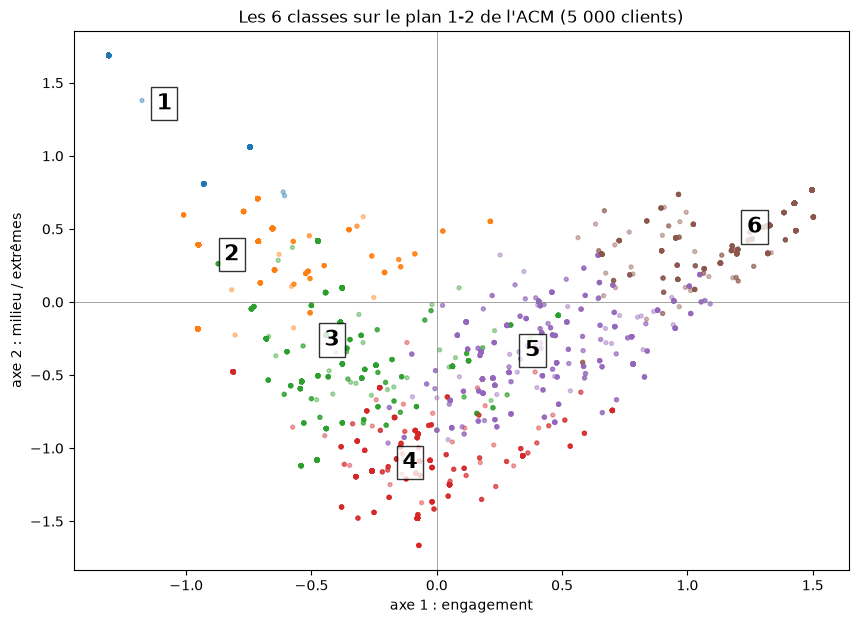

In [25]:
plt.figure(figsize=(10, 7))
points = X.sample(5000, random_state=1)
plt.scatter(points["axe_1"], points["axe_2"], c=ech.loc[points.index, "cluster"], cmap="tab10", vmin=1, vmax=10, s=8, alpha=0.4)
for c in range(1, 7):
    centre = X[ech["cluster"] == c].mean()
    plt.text(centre["axe_1"], centre["axe_2"], str(c), fontsize=16, fontweight="bold",
             ha="center", va="center", bbox=dict(facecolor="white", alpha=0.8))
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.xlabel("axe 1 : engagement")
plt.ylabel("axe 2 : milieu / extrêmes")
plt.title("Les 6 classes sur le plan 1-2 de l'ACM (5 000 clients)")
plt.savefig("../outputs/figures/clusters_plan_acm.png", dpi=100, bbox_inches="tight")
plt.show()

Sur le plan 1-2, les classes se rangent le long de la parabole de l'effet Guttman, de la classe 1 (à gauche) à la classe 6 (à droite). Les points sont superposés car beaucoup de clients ont exactement le même profil (607 profils différents).

## 5. Description des classes

Comme le demande le cours, on décrit le contenu de chaque classe avec des statistiques descriptives : pour chaque variable (active et illustrative), la répartition des modalités dans chaque classe, comparée à l'ensemble des clients.

### 5.1 Quelles variables distinguent les classes ? (tests du khi-deux)

Pour chaque variable, test du khi-deux d'indépendance avec la classe, et V de Cramér. Comme dans le v2, avec 68 214 clients les p-values sont presque toujours nulles : on lit surtout le V de Cramér.

In [26]:
def test_cluster(var):
    tableau = pd.crosstab(ech[var], ech["cluster"])
    chi2, p_value, ddl, attendus = chi2_contingency(tableau)
    v = np.sqrt(chi2 / (len(ech) * (min(tableau.shape) - 1)))
    return [var, chi2, p_value, v]


lignes = [test_cluster(var) for var in actives + illustratives]
tests = pd.DataFrame(lignes, columns=["variable", "khi2", "p_value", "V_cramer"])
tests["role"] = ["active"] * len(actives) + ["illustrative"] * len(illustratives)
tests.sort_values("V_cramer", ascending=False).round(3)

,variable,khi2,p_value,V_cramer,role
3,nb_abo_periode,240001.869,0.0,0.938,active
4,valeur_12M_tr,204297.917,0.0,0.774,active
5,type_client,77464.830,0.0,0.615,illustrative
2,ratio_fidelite_tr,96476.810,0.0,0.532,active
0,anciennete_client_tr,69707.099,0.0,0.505,active
1,anciennete_abonnement_tr,69421.726,0.0,0.504,active
6,avg_sessions_actifs_tr,11713.453,0.0,0.207,illustrative
13,contactable,1114.223,0.0,0.128,illustrative
11,type_very_first_abo,567.081,0.0,0.091,illustrative
8,utilise_remote,387.427,0.0,0.075,illustrative


- Les 5 variables actives sont très liées aux classes (V de 0,50 à 0,94), ce qui est attendu puisqu'elles les ont construites. `nb_abo_periode` est presque à 1 : **la classe d'un client dépend d'abord de son nombre de mois d'abonnement sur la période.**
- `type_client` (illustrative) est très liée aussi (0,62) : la typologie retrouve le statut de fidélité sans l'avoir utilisé.
- Les variables d'usage, de paiement et de zone sont toutes significatives (p-value < 0,05) mais faiblement liées (V de 0,06 à 0,21). Elles nuancent les portraits, elles ne les définissent pas.

### 5.2 Profil des classes

Pour chaque variable : % des clients de la classe qui ont la modalité (colonnes 1 à 6) et % dans l'ensemble des clients. Une modalité caractérise une classe quand son % est nettement au-dessus de celui de l'ensemble.

In [27]:
def profil(var):
    tableau = pd.crosstab(ech[var], ech["cluster"], normalize="columns") * 100
    tableau["ensemble"] = ech[var].value_counts(normalize=True) * 100
    return tableau.round(1)


for var in actives:
    print("===", var)
    print(profil(var))
    print()

=== anciennete_client_tr
cluster                   1     2     3     4     5     6  ensemble
anciennete_client_tr                                               
01_moins_3_mois       100.0   0.0  20.5   0.0   0.0   0.0      10.5
02_3a5_mois             0.0  12.5   8.0  37.2   0.0   0.0       9.5
03_6a12_mois            0.0  50.8  32.9  23.1  41.2   5.1      28.7
04_13a24_mois           0.0  14.8  15.8  15.9  23.3  27.7      18.4
05_25_mois_et_plus      0.0  22.0  22.8  23.7  35.5  67.2      32.9

=== anciennete_abonnement_tr
cluster                       1     2     3     4     5     6  ensemble
anciennete_abonnement_tr                                               
01_moins_3_mois           100.0   5.9  38.2  15.2  15.4   2.0      20.4
02_3a5_mois                 0.0  17.3  13.1  51.0  10.0   1.6      15.6
03_6a12_mois                0.0  71.9  40.3  23.8  56.7  11.1      38.6
04_13a24_mois               0.0   4.0   6.6   6.8  12.2  36.9      13.1
05_25_mois_et_plus          0.0   1.0

In [28]:
for var in illustratives:
    print("===", var)
    print(profil(var))
    print()

=== type_client
cluster         1     2     3     4     5     6  ensemble
type_client                                              
churn        40.1  96.6  68.9  57.5  33.9   1.6      50.5
nouveau      59.8   0.0  17.9  22.7  26.1   2.5      15.9
reactivated   0.1   3.4  13.2  19.9  37.5   8.3      14.6
retained      0.0   0.0   0.0   0.0   2.5  87.6      18.9

=== avg_sessions_actifs_tr
cluster                    1     2     3     4     5     6  ensemble
avg_sessions_actifs_tr                                              
00_pas_de_session       10.1  16.8  11.6  10.5   8.6  12.3      12.0
01_moins_1               0.0   0.0  17.8  28.7  35.8  27.5      19.8
02_1a5                  68.5  69.0  58.4  47.4  37.9  32.0      50.4
04_5a10                 15.6  11.5   8.4   7.9   9.6  12.8      10.6
05_10_et_plus            5.8   2.8   3.8   5.5   8.1  15.3       7.2

=== avg_songs_sessions_tr
cluster                   1     2     3     4     5     6  ensemble
avg_songs_sessions_tr         

### 5.3 Vue d'ensemble

Pour la lecture et la présentation : quelques indicateurs simples par classe, tirés des tableaux ci-dessus.

In [29]:
synthese = pd.DataFrame({
    "pct_clients": ech["cluster"].value_counts(normalize=True).sort_index() * 100,
    "pct_churn": (ech["type_client"] == "churn").groupby(ech["cluster"]).mean() * 100,
    "pct_retained": (ech["type_client"] == "retained").groupby(ech["cluster"]).mean() * 100,
    "pct_nouveau": (ech["type_client"] == "nouveau").groupby(ech["cluster"]).mean() * 100,
    "pct_reactivated": (ech["type_client"] == "reactivated").groupby(ech["cluster"]).mean() * 100,
    "pct_sans_session": (ech["avg_sessions_actifs_tr"] == "00_pas_de_session").groupby(ech["cluster"]).mean() * 100,
    "pct_5_sessions_et_plus": ech["avg_sessions_actifs_tr"].isin(["04_5a10", "05_10_et_plus"]).groupby(ech["cluster"]).mean() * 100,
    "pct_remote": (ech["utilise_remote"] == "oui").groupby(ech["cluster"]).mean() * 100,
    "pct_US": (ech["zone_geo"] == "US").groupby(ech["cluster"]).mean() * 100,
    "pct_contactable": (ech["contactable"] == "oui").groupby(ech["cluster"]).mean() * 100,
})
synthese.loc["ensemble"] = [100,
    (ech["type_client"] == "churn").mean() * 100,
    (ech["type_client"] == "retained").mean() * 100,
    (ech["type_client"] == "nouveau").mean() * 100,
    (ech["type_client"] == "reactivated").mean() * 100,
    (ech["avg_sessions_actifs_tr"] == "00_pas_de_session").mean() * 100,
    ech["avg_sessions_actifs_tr"].isin(["04_5a10", "05_10_et_plus"]).mean() * 100,
    (ech["utilise_remote"] == "oui").mean() * 100,
    (ech["zone_geo"] == "US").mean() * 100,
    (ech["contactable"] == "oui").mean() * 100,
]
synthese.round(1)

,pct_clients,pct_churn,pct_retained,pct_nouveau,pct_reactivated,pct_sans_session,pct_5_sessions_et_plus,pct_remote,pct_US,pct_contactable
cluster,,,,,,,,,,
1,6.7,40.1,0.0,59.8,0.1,10.1,21.4,26.7,35.8,73.0
2,20.9,96.6,0.0,0.0,3.4,16.8,14.2,21.7,32.0,55.8
3,18.5,68.9,0.0,17.9,13.2,11.6,12.2,27.1,38.2,62.5
4,14.5,57.5,0.0,22.7,19.9,10.5,13.4,28.3,41.6,65.7
5,18.2,33.9,2.5,26.1,37.5,8.6,17.7,28.3,46.1,61.6
6,21.1,1.6,87.6,2.5,8.3,12.3,28.1,20.8,50.4,50.8
ensemble,100.0,50.5,18.9,15.9,14.6,12.0,17.8,25.0,41.2,59.6


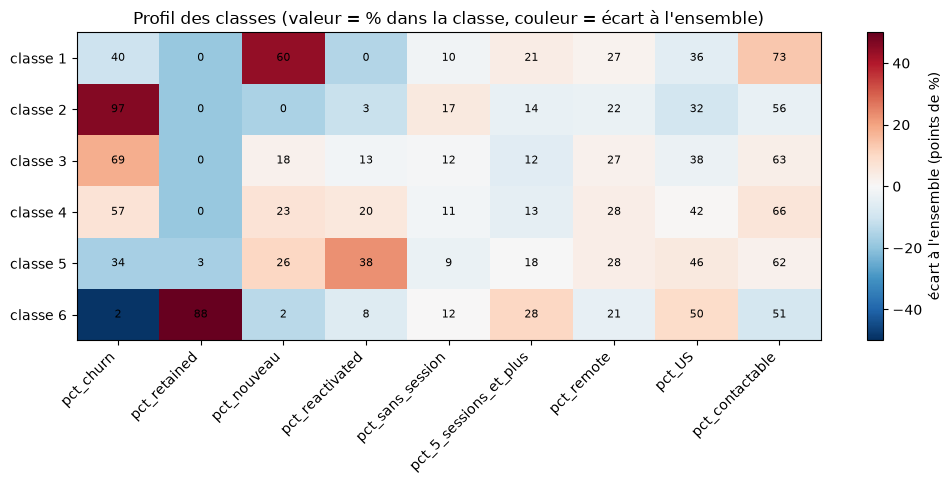

In [30]:
# carte des profils : écart (en points) entre la classe et l'ensemble
ecarts = synthese.drop("ensemble").drop(columns="pct_clients") - synthese.loc["ensemble"].drop("pct_clients")

plt.figure(figsize=(12, 4))
plt.imshow(ecarts, cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
plt.colorbar(label="écart à l'ensemble (points de %)")
plt.xticks(range(ecarts.shape[1]), ecarts.columns, rotation=45, ha="right")
plt.yticks(range(6), ["classe " + str(c) for c in ecarts.index])
for i in range(ecarts.shape[0]):
    for j in range(ecarts.shape[1]):
        plt.text(j, i, round(synthese.iloc[i, j + 1]), ha="center", va="center", fontsize=8)
plt.title("Profil des classes (valeur = % dans la classe, couleur = écart à l'ensemble)")
plt.savefig("../outputs/figures/clusters_profils.png", dpi=100, bbox_inches="tight")
plt.show()

### 5.4 Portraits

À partir des tableaux des parties 5.2 et 5.3 :

| Classe | Nom | % | Portrait |
|---|---|---|---|
| 1 | **Les nouveaux arrivants** | 6,7 % | 1 seul mois d'abonnement, mais arrivés il y a moins de 3 mois (100 %). 60 % de nouveaux, 40 % déjà partis après ce premier mois. Plutôt actifs : 21 % font 5 sessions ou plus par mois (18 % en moyenne). Les plus contactables (73 %). |
| 2 | **Les partis après un mois** | 20,9 % | 1 seul mois d'abonnement sur la période et moins de 10 de valeur (99 %). Arrivés il y a 6 à 12 mois pour la moitié, ratio de fidélité sous 30 % (92 %). 97 % sont partis (churn). Ce sont aussi les clients qui ont le moins utilisé l'application : 17 % n'ont fait aucune session (12 % en moyenne) et seulement 14 % font 5 sessions ou plus par mois. |
| 3 | **Les testeurs** | 18,5 % | 2 à 3 mois d'abonnement, 10 à 20 de valeur. 69 % sont déjà partis. Un client sur trois a un ratio de fidélité sous 30 % : ce sont des clients qui ont essayé quelques mois sans accrocher. |
| 4 | **Les intermédiaires** | 14,5 % | 4 à 6 mois d'abonnement, 20 à 40 de valeur, abonnement en cours depuis 3 à 5 mois pour la moitié. 57 % de churn, mais 20 % de réactivés : ils hésitent, partent et reviennent. |
| 5 | **Les réguliers** | 18,2 % | 7 à 11 mois d'abonnement, 40 à 70 de valeur, ratio de fidélité élevé (75 % au-dessus de 70 %). Mélange de réactivés (38 %), de nouveaux arrivés en cours d'année (26 %) et de partis (34 %). Plus américains (46 %) que la moyenne. |
| 6 | **Les fidèles** | 21,1 % | 12 mois sur 12, plus de 70 de valeur (96 %), clients depuis plus de 2 ans pour les deux tiers. 88 % de retained. Les plus gros utilisateurs (28 % à 5 sessions ou plus) et les plus américains (50 %), plus souvent Paypal. Mais seulement la moitié est contactable. |

Les numéros suivent la position sur l'axe 1 (partie 4.3). Les classes 1 et 2 ont toutes les deux un seul mois d'abonnement : les nouveaux arrivants sont un peu plus à gauche sur l'axe 1, mais ils ne sont pas « moins engagés » que les partis, ils n'ont simplement pas encore eu le temps de l'être. De la classe 2 à la classe 6, le nombre de mois d'abonnement augmente.

## 6. Affectation : rendre la typologie opérationnelle

La classification a été construite une fois, sur l'échantillon. Pour l'utiliser, le marketing doit pouvoir donner une classe à **n'importe quel client**, y compris aux nouveaux et aux clients dont le comportement change. Le cours propose deux façons : des règles simples, ou un modèle (ici une **régression logistique généralisée**, comme `proc logistic ... link=glogit` en SAS : une régression logistique multinomiale, qui donne la probabilité d'appartenir à chacune des 6 classes).

### 6.1 Régression logistique

Variables explicatives : les 5 variables actives, en indicatrices (une colonne par modalité). On apprend le modèle sur 70 % de l'échantillon et on le teste sur les 30 % restants, pour mesurer sa qualité sur des clients qu'il n'a pas vus.

In [31]:
X_logit = pd.get_dummies(ech[actives]).astype(float)
y = ech["cluster"]

X_apprentissage, X_test, y_apprentissage, y_test = train_test_split(
    X_logit, y, test_size=0.3, random_state=1, stratify=y)

modele = LogisticRegression(max_iter=2000)
modele.fit(X_apprentissage, y_apprentissage)

print("taux de bien classés, apprentissage :", round(accuracy_score(y_apprentissage, modele.predict(X_apprentissage)) * 100, 2), "%")
print("taux de bien classés, test          :", round(accuracy_score(y_test, modele.predict(X_test)) * 100, 2), "%")

taux de bien classés, apprentissage : 99.89 %
taux de bien classés, test          : 99.89 %


In [32]:
pd.DataFrame(confusion_matrix(y_test, modele.predict(X_test)),
             index=["vraie " + str(c) for c in range(1, 7)],
             columns=["prédite " + str(c) for c in range(1, 7)])

,prédite 1,prédite 2,prédite 3,prédite 4,prédite 5,prédite 6
vraie 1,1369,0,1,0,0,0
vraie 2,0,4283,0,0,0,0
vraie 3,0,2,3783,1,1,0
vraie 4,0,0,6,2967,0,0
vraie 5,0,0,0,1,3727,5
vraie 6,0,0,0,0,5,4314


Le modèle retrouve la bonne classe pour 99,9 % des clients de test, aussi bien qu'en apprentissage : il n'y a pas de sur-apprentissage. Les rares erreurs sont entre classes voisines (fidèles / réguliers, testeurs / intermédiaires).

Ce score très élevé n'est pas étonnant : les classes ont été construites à partir de ces 5 variables, et il n'y a que 607 profils possibles. Le modèle apprend en fait à quel groupe appartient chaque profil.

### 6.2 Et avec des règles simples ?

Puisque `nb_abo_periode` est presque identique à la classe (V = 0,94), on teste une règle que n'importe qui peut appliquer sans modèle :

In [33]:
def regle_simple(data):
    classe = data["nb_abo_periode"].map({
        "01_1_abo": 2,
        "02_2a3_abo": 3,
        "03_4a6_abo": 4,
        "04_7a11_abo": 5,
        "05_12_abo": 6,
    })
    # parmi les clients à 1 mois, ceux arrivés depuis moins de 3 mois sont les nouveaux arrivants
    nouveaux = (data["nb_abo_periode"] == "01_1_abo") & (data["anciennete_client_tr"] == "01_moins_3_mois")
    classe[nouveaux] = 1
    return classe


print("taux de bien classés avec la règle :", round((regle_simple(ech) == ech["cluster"]).mean() * 100, 1), "%")
pd.crosstab(regle_simple(ech), ech["cluster"], rownames=["règle"], colnames=["vraie classe"])

taux de bien classés avec la règle : 95.5 %


vraie classe,1,2,3,4,5,6
règle,,,,,,
1,4565,0,0,0,0,0
2,0,14233,44,777,0,0
3,3,42,12553,541,0,55
4,0,0,23,8572,1222,0
5,0,0,1,18,11091,230
6,0,0,1,1,130,14112


**Décision : on garde la régression logistique pour l'affectation, et la règle simple pour la communication.**

- La règle classe bien 95,5 % des clients. Elle est très pratique pour expliquer les classes au marketing (« un fidèle, c'est un client abonné 12 mois sur 12 »).
- Mais elle se trompe sur 4,5 % des clients, surtout aux frontières : des clients à 4-6 mois qui ressemblent en fait aux réguliers, des clients à 2-3 mois qui ressemblent aux intermédiaires. Le modèle, qui tient compte des 5 variables, ne se trompe que sur 0,1 %.

### 6.3 Application à toute la base

On applique le modèle aux 341 069 clients. Il faut d'abord leur appliquer les mêmes regroupements qu'à l'échantillon (partie 1).

Pour vérifier le modèle sur les 272 855 clients qui n'étaient pas dans l'échantillon, on calcule aussi la classe « de référence » : on place ces clients sur les axes de l'ACM et on les met dans la classe dont le centre est le plus proche. Les deux méthodes doivent donner la même classe.

In [34]:
base = regroupements_acm(df2)

# régression logistique
X_base = pd.get_dummies(base[actives]).astype(float)[X_logit.columns]
base["cluster"] = modele.predict(X_base)

# classe de référence : coordonnées sur les axes de l'ACM, puis centre le plus proche
Z_base = pd.get_dummies(base[actives], prefix_sep=" = ").astype(float)[res["Z"].columns]
X_base_acm = coord_clients(res, Z_base, nb_axes)
reference = pd.Series(kmeans.predict(pd.DataFrame(X_base_acm, columns=axes)), index=base.index).map(nouveau_numero)

hors_echantillon = ~base.index.isin(ech.index)
print("clients hors échantillon :", hors_echantillon.sum())
print("même classe avec les deux méthodes :", round((base.loc[hors_echantillon, "cluster"] == reference[hors_echantillon]).mean() * 100, 2), "%")

clients hors échantillon : 272855
même classe avec les deux méthodes : 99.89 %


In [35]:
pd.DataFrame({
    "echantillon_pct": ech["cluster"].value_counts(normalize=True).sort_index() * 100,
    "base_complete_pct": base["cluster"].value_counts(normalize=True).sort_index() * 100,
    "base_complete_effectif": base["cluster"].value_counts().sort_index(),
}).round(1)

,echantillon_pct,base_complete_pct,base_complete_effectif
cluster,,,
1,6.7,6.6,22659
2,20.9,20.7,70497
3,18.5,18.6,63509
4,14.5,14.5,49540
5,18.2,18.3,62446
6,21.1,21.2,72418


Sur les clients hors échantillon, le modèle donne la même classe que la méthode de référence dans 99,9 % des cas, et la répartition des classes sur toute la base est la même que sur l'échantillon (écarts de 0,1 point au plus). La typologie se généralise bien à l'ensemble des clients.

### 6.4 Enregistrement

On enregistre la classe de chaque client, avec le nom de la classe, pour que le marketing puisse l'utiliser (ciblage des campagnes).

In [36]:
noms = {
    1: "Nouveaux arrivants",
    2: "Partis après un mois",
    3: "Testeurs",
    4: "Intermédiaires",
    5: "Réguliers",
    6: "Fidèles",
}
base["segment"] = base["cluster"].map(noms)

base[["id_anonyme", "cluster", "segment"]].to_csv("../data/processed/clients_segments.csv", index=False)
base["segment"].value_counts()

segment
Fidèles                 72418
Partis après un mois    70497
Testeurs                63509
Réguliers               62446
Intermédiaires          49540
Nouveaux arrivants      22659
Name: count, dtype: int64

## 7. Bilan

**Démarche (méthode du cours en 3 étapes) :**
1. ACM sur 5 variables actives liées à l'abonnement : 5 axes gardés (critères 50 % d'inertie et Benzécri 95 %). L'axe 1 est l'engagement.
2. Classification mixte : CAH de Ward sur 10 000 clients pour choisir le nombre de classes (SPRSQ, R², pseudo-F : 6 classes), puis k-means sur les 68 214 clients de l'échantillon en partant des centres de la CAH. R² = 0,81.
3. Affectation par régression logistique multinomiale : 99,9 % de bien classés sur l'échantillon de test et sur les clients hors échantillon. Classe enregistrée pour les 341 069 clients.

**Tests de robustesse :** même résultat avec deux sous-échantillons de CAH différents, et avec des k-means au hasard (ARI ≥ 0,998).

**Les 6 segments :** nouveaux arrivants (7 %), partis après un mois (21 %), testeurs (18 %), intermédiaires (15 %), réguliers (18 %), fidèles (21 %).

**Limites, à garder en tête pour la présentation :**
- La typologie est surtout une typologie de l'**engagement dans l'abonnement** : la classe dépend d'abord du nombre de mois d'abonnement sur la période (V = 0,94, règle simple juste à 95 %). C'est la conséquence du choix des variables actives fait dans le v2 (les variables d'usage ne construisaient aucun axe).
- L'usage (sessions, remote), le paiement et la zone ne distinguent que faiblement les classes (V ≤ 0,21) : ils servent à nuancer les portraits, pas à les définir.
- La période d'observation fait 12 mois : un client peut changer de classe d'une année à l'autre. Il faudra refaire l'affectation régulièrement (par exemple tous les mois) avec le modèle de la partie 6.